# Machine Translation: English to Esperanto with Four Architectures
### Foundations of Generative AI (ICT4403), Assignment 3

This notebook builds and compares four machine-translation systems for English to Esperanto:

| System | Architecture |
|---|---|
| Basic Transformer | encoder-decoder Transformer |
| mT5-style | encoder-decoder (T5 / mT5 family) |
| LLaMA-style | decoder-only causal language model |
| Gemma-style | decoder-only causal language model |

A pretrained MarianMT model is evaluated on the same test set as a reference point.

All four required systems are trained from scratch on the same parallel corpus, with the same
tokenizer, the same data split and the same training budget, so the comparison is like for like.

**Note on compute.** This machine has no GPU and limited memory, so pretrained checkpoints of the
mT5, LLaMA and Gemma families (300 million to 2 billion parameters) cannot be hosted. Following the
brief's allowance for *suitable smaller model variants according to the available computational
resources*, each architecture is instantiated in a compact configuration (about 0.2 to 0.4 million
parameters) and trained from scratch. Training the four models takes several minutes on CPU, so this
notebook reuses checkpoints from `models/` when they are present and retrains only if they are absent.

## 0. Configuration and imports

In [1]:
import os, json, time, math, random, gc, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import sacrebleu
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

VOCAB_SIZE = 2000
MAXLEN     = 14
BATCH      = 64
LR         = 1e-3
EPOCHS     = 5
TRAIN_N    = 8000
MAX_WORDS  = 10
TEST_N     = 100
D_MODEL    = 64
N_HEAD     = 2
N_LAYER    = 1
D_FF       = 128
PAD, UNK, BOS, EOS = 0, 1, 2, 3

BASE_URL = 'https://huggingface.co/datasets/Helsinki-NLP/opus-100/resolve/main/en-eo'

def download():
    os.makedirs('data', exist_ok=True)
    for sp in ['train', 'validation', 'test']:
        p = f'data/en-eo_{sp}.parquet'
        if not os.path.exists(p):
            urllib.request.urlretrieve(f'{BASE_URL}/{sp}-00000-of-00001.parquet', p)
    return True

def load_pairs():
    import pyarrow as pa, pyarrow.parquet as pq
    pa.set_cpu_count(1); pa.set_io_thread_count(1)
    def subset(split, n, shuffle=True):
        t = pq.read_table(f'data/en-eo_{split}.parquet').flatten()
        idx = sorted(random.Random(SEED).sample(range(t.num_rows), min(n, t.num_rows))) if shuffle \
              else list(range(min(n, t.num_rows)))
        rows = []
        for r in t.take(pa.array(idx)).to_pylist():
            en = (r['translation.en'] or '').strip(); eo = (r['translation.eo'] or '').strip()
            if en and eo:
                rows.append({'en': en, 'eo': eo})
        return rows
    return subset('train', TRAIN_N), subset('validation', 500, False), subset('test', TEST_N, False)

def keep(r, max_words=MAX_WORDS, max_ratio=2.0):
    a, b = len(r['en'].split()), len(r['eo'].split())
    if a == 0 or b == 0 or a > max_words or b > max_words:
        return False
    return max(a, b) / min(a, b) <= max_ratio

def build_tokenizer(train):
    import sentencepiece as spm
    with open('data/spm_corpus.txt', 'w', encoding='utf-8') as f:
        for r in train:
            f.write(r['en'] + '\n'); f.write(r['eo'] + '\n')
    spm.SentencePieceTrainer.train(
        input='data/spm_corpus.txt', model_prefix='data/spm', vocab_size=VOCAB_SIZE,
        model_type='bpe', character_coverage=1.0, pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        pad_piece='<pad>', unk_piece='<unk>', bos_piece='<s>', eos_piece='</s>', num_threads=1)
    return spm.SentencePieceProcessor(model_file='data/spm.model')

## 1. Dataset: English to Esperanto

**Source:** OPUS-100, configuration `en-eo` (Helsinki-NLP), a public multilingual parallel corpus
built from OPUS. Source link:
https://huggingface.co/datasets/Helsinki-NLP/opus-100

Esperanto is a constructed international language with a regular grammar and Latin-script diacritics
(ĉ, ĝ, ĥ, ĵ, ŝ, ŭ). It is a deliberately unusual choice: most MT coursework uses French, German or
Hindi, and Esperanto's regularity and its small mixed-domain corpus make it a useful low-resource test
case.

We download the parquet files directly and take a manageable subset.

In [2]:
download()
train_raw, val_raw, test_raw = load_pairs()
print('sampled pairs  train/val/test:', len(train_raw), len(val_raw), len(test_raw))

sampled pairs  train/val/test: 8000 500 100


### Preprocessing and filtering

OPUS-100 is a crawled corpus and contains noisy pairs: misaligned segments, very long sentences and
occasional language leakage. A pair is kept only if both sides are non-empty, both sides are at most
10 words long, and the length ratio between the sides is at most 2.0. Restricting to short sentences
also makes training feasible on a CPU, and it is stated explicitly as part of the experimental setup.

In [3]:
train = [r for r in train_raw if keep(r)]
val   = [r for r in val_raw if keep(r)]
test  = [r for r in test_raw if keep(r)]

def stats(rows, key):
    w = sorted(len(r[key].split()) for r in rows)
    return dict(avg=round(sum(w)/len(w), 2), p95=w[int(0.95*len(w))-1], max=w[-1])

print('after filtering  train/val/test:', len(train), len(val), len(test))
print('train EN', stats(train, 'en'), '| train EO', stats(train, 'eo'))
print('test  EN', stats(test, 'en'))
print()
for r in train[:3]:
    print(' EN:', r['en'])
    print(' EO:', r['eo'])

after filtering  train/val/test: 6496 403 82
train EN {'avg': 4.49, 'p95': 9, 'max': 10} | train EO {'avg': 4.28, 'p95': 9, 'max': 10}
test  EN {'avg': 5.52, 'p95': 9, 'max': 10}

 EN: Brendan!
 EO: Brendano!
 EN: Trece Martires City
 EO: philippines. kgm
 EN: Select the folder containing the runlevel folders
 EO: Elektu la dosierujon enhavanta la rulnivelo- dosierujojn


## 2. Tokenization

A single shared BPE vocabulary is trained with SentencePiece on the training pairs, covering both
languages. Source and target therefore share one tokenizer and one embedding matrix, and the same
tokenizer is used for all four models. Esperanto diacritics are handled as ordinary Unicode.

In [4]:
import sentencepiece as spm
if os.path.exists('data/spm.model'):
    sp = spm.SentencePieceProcessor(model_file='data/spm.model')
    print('loaded existing tokenizer')
else:
    sp = build_tokenizer(train)
V = sp.get_piece_size()
print('vocabulary size:', V)
print('Esperanto:', sp.encode('La kato dormas sur la mato.', out_type=str))
print('English  :', sp.encode('The cat sleeps on the mat.', out_type=str))

loaded existing tokenizer
vocabulary size: 2000
Esperanto: ['▁La', '▁k', 'ato', '▁d', 'orm', 'as', '▁sur', '▁la', '▁m', 'ato', '.']
English  : ['▁The', '▁c', 'at', '▁s', 'le', 'ep', 's', '▁on', '▁the', '▁mat', '.']


In [5]:
srcs = [r['en'] for r in test]
refs = [r['eo'] for r in test]
print('test sentences:', len(srcs))

# Pretrained reference. It runs in a separate process (marian_ref.py) because the
# notebook kernel's own imports already occupy much of the available memory.
import subprocess, sys
REF_NAME = 'MarianMT (pretrained reference)'
marian = None
json.dump({'srcs': srcs, 'refs': refs}, open('data/test_srcs.json', 'w'), ensure_ascii=False)
try:
    proc = subprocess.run([sys.executable, 'marian_ref.py'], capture_output=True, text=True)
    print(proc.stdout.strip()[-400:])
    if proc.returncode != 0:
        print('reference subprocess stderr:', proc.stderr.strip()[-300:])
    if os.path.exists('data/marian.json'):
        marian = json.load(open('data/marian.json', encoding='utf-8'))
        print('MarianMT reference: BLEU %.2f  chrF %.2f  params %.1fM'
              % (marian['bleu'], marian['chrf'], marian['params']/1e6))
except Exception as e:
    print('reference model unavailable:', type(e).__name__, str(e)[:200])

test sentences: 82


MarianMT BLEU 52.79  chrF 71.58  params 75.0M  infer 34.6s
MarianMT reference: BLEU 52.79  chrF 71.58  params 75.0M


## 3. The four models

All four are deliberately compact because this machine has no GPU. They share the same embedding
size, feed-forward width and tokenizer.

* **Basic Transformer**: standard encoder-decoder (`nn.Transformer`) with learned positional
  embeddings and a linear softmax head.
* **mT5-style**: `T5ForConditionalGeneration` with a small T5/mT5 configuration (relative position
  bias, no absolute position embeddings).
* **LLaMA-style**: `LlamaForCausalLM` with a compact configuration (rotary position embeddings,
  grouped-query attention).
* **Gemma-style**: `GemmaForCausalLM` with a compact configuration.

The two decoder-only models are adapted to translation with a prompt prefix of the form
`translate English to Esperanto: <english> =>`; the loss is computed only on the Esperanto
continuation.

In [6]:
def make_encdec(sp, pairs):
    S = torch.zeros(len(pairs), MAXLEN, dtype=torch.long)
    T = torch.zeros(len(pairs), MAXLEN, dtype=torch.long)
    for i, r in enumerate(pairs):
        a = sp.encode(r['en'], out_type=int)[:MAXLEN-1]
        b = sp.encode(r['eo'], out_type=int)[:MAXLEN-2]
        S[i, 0] = BOS; S[i, 1:1+len(a)] = torch.tensor(a)
        T[i, 0] = BOS; T[i, 1:1+len(b)] = torch.tensor(b); T[i, 1+len(b)] = EOS
    return S, T

PROMPT = 'translate English to Esperanto: '
SEP = ' => '

def make_causal(sp, pairs):
    L2 = 2 * MAXLEN
    X = torch.zeros(len(pairs), L2, dtype=torch.long)
    Y = torch.full((len(pairs), L2), -100, dtype=torch.long)
    for i, r in enumerate(pairs):
        p = sp.encode(PROMPT + r['en'] + SEP, out_type=int)[:MAXLEN]
        t = sp.encode(r['eo'], out_type=int)[:MAXLEN-1]
        seq = (p + t + [EOS])[:L2]
        X[i, :len(seq)] = torch.tensor(seq)
        Y[i, len(p):len(seq)] = torch.tensor(seq[len(p):])
    return X, Y

from transformers import (T5Config, T5ForConditionalGeneration,
                          LlamaConfig, LlamaForCausalLM,
                          GemmaConfig, GemmaForCausalLM)

class BasicTransformer(nn.Module):
    def __init__(self, vocab, d=D_MODEL, heads=N_HEAD, ff=D_FF, maxlen=MAXLEN, drop=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=PAD)
        self.pos = nn.Embedding(maxlen, d)
        self.tr = nn.Transformer(d_model=d, nhead=heads, num_encoder_layers=N_LAYER,
                                 num_decoder_layers=N_LAYER, dim_feedforward=ff,
                                 dropout=drop, batch_first=True)
        self.out = nn.Linear(d, vocab)
    def forward(self, src, tgt):
        s = self.emb(src) + self.pos(torch.arange(src.size(1)).unsqueeze(0))
        t = self.emb(tgt) + self.pos(torch.arange(tgt.size(1)).unsqueeze(0))
        mask = nn.Transformer.generate_square_subsequent_mask(tgt.size(1))
        h = self.tr(s, t, tgt_mask=mask, src_key_padding_mask=(src == PAD),
                    tgt_key_padding_mask=(tgt == PAD))
        return self.out(h)

def build_model(name, V):
    if name == 'Basic Transformer':
        return BasicTransformer(V), 'encdec'
    if name == 'mT5-style':
        cfg = T5Config(vocab_size=V, d_model=D_MODEL, d_ff=D_FF, num_layers=N_LAYER,
                       num_decoder_layers=N_LAYER, num_heads=N_HEAD,
                       decoder_start_token_id=PAD, pad_token_id=PAD, eos_token_id=EOS)
        return T5ForConditionalGeneration(cfg), 'hf_encdec'
    if name == 'LLaMA-style':
        cfg = LlamaConfig(vocab_size=V, hidden_size=D_MODEL, intermediate_size=D_FF,
                          num_hidden_layers=N_LAYER, num_attention_heads=N_HEAD,
                          num_key_value_heads=N_HEAD, max_position_embeddings=4*MAXLEN,
                          pad_token_id=PAD)
        return LlamaForCausalLM(cfg), 'causal'
    if name == 'Gemma-style':
        cfg = GemmaConfig(vocab_size=V, hidden_size=D_MODEL, intermediate_size=D_FF,
                          num_hidden_layers=N_LAYER, num_attention_heads=N_HEAD,
                          num_key_value_heads=N_HEAD, head_dim=D_MODEL // N_HEAD,
                          max_position_embeddings=4*MAXLEN, pad_token_id=PAD)
        return GemmaForCausalLM(cfg), 'causal'
    raise ValueError(name)

/scratch/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
for name in ['Basic Transformer', 'mT5-style', 'LLaMA-style', 'Gemma-style']:
    m, kind = build_model(name, V)
    print(f'{name:20s} kind={kind:12s} params={sum(p.numel() for p in m.parameters())/1e6:.3f}M')

Basic Transformer    kind=encdec       params=0.343M
mT5-style            kind=hf_encdec    params=0.260M
LLaMA-style          kind=causal       params=0.297M
Gemma-style          kind=causal       params=0.169M


## 4. Training

Every model uses the same optimiser (Adam), learning rate, batch size, number of epochs and data.
Training time is recorded for each model. If a checkpoint is already present it is loaded and the
recorded training time is reused; delete the `models/` folder to retrain from scratch.

In [8]:
def batch_loss(model, kind, src, tgt, V):
    if kind == 'encdec':
        out = model(src, tgt[:, :-1])
        return F.cross_entropy(out.reshape(-1, V), tgt[:, 1:].reshape(-1), ignore_index=PAD)
    if kind == 'hf_encdec':
        labels = tgt.clone(); labels[labels == PAD] = -100
        return model(input_ids=src, labels=labels).loss
    return model(input_ids=src, labels=tgt).loss

def prepare(sp, pairs, kind):
    return make_encdec(sp, pairs) if kind in ('encdec', 'hf_encdec') else make_causal(sp, pairs)

def train_model(name, sp, V, train, epochs=EPOCHS, bs=BATCH, lr=LR, verbose=True):
    torch.manual_seed(SEED)
    model, kind = build_model(name, V)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    t0 = time.time(); curve = []
    for ep in range(1, epochs + 1):
        data = train[:]
        random.Random(SEED + ep).shuffle(data)
        tot, nb = 0.0, 0
        for i in range(0, len(data), bs):
            src, tgt = prepare(sp, data[i:i+bs], kind)
            opt.zero_grad()
            loss = batch_loss(model, kind, src, tgt, V)
            loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        curve.append(tot / nb)
        if verbose:
            print(f'  epoch {ep}/{epochs}  train loss {curve[-1]:.4f}')
    return model, kind, time.time() - t0, curve

def _src_tensor(sp, srcs):
    S = torch.zeros(len(srcs), MAXLEN, dtype=torch.long)
    for i, s in enumerate(srcs):
        a = sp.encode(s, out_type=int)[:MAXLEN-1]
        S[i, 0] = BOS; S[i, 1:1+len(a)] = torch.tensor(a)
    return S

def translate_greedy(model, kind, sp, srcs, V):
    model.eval()
    if kind == 'encdec':
        S = _src_tensor(sp, srcs)
        ys = torch.full((len(srcs), 1), BOS, dtype=torch.long)
        done = torch.zeros(len(srcs), dtype=torch.bool)
        with torch.no_grad():
            for _ in range(MAXLEN):
                nxt = model(S, ys)[:, -1].argmax(-1)
                ys = torch.cat([ys, nxt.unsqueeze(1)], 1)
                done |= (nxt == EOS)
                if bool(done.all()):
                    break
        out = []
        for row in ys[:, 1:]:
            toks = []
            for t in row.tolist():
                if t == EOS: break
                toks.append(t)
            out.append(sp.decode(toks))
        return out
    if kind == 'hf_encdec':
        S = _src_tensor(sp, srcs)
        with torch.no_grad():
            gen = model.generate(input_ids=S, attention_mask=(S != PAD), max_new_tokens=MAXLEN,
                                 num_beams=1, do_sample=False, pad_token_id=PAD, eos_token_id=EOS)
        return [sp.decode([t for t in row.tolist() if t not in (PAD, EOS)]) for row in gen]
    out = []
    for s in srcs:
        p = sp.encode(PROMPT + s + SEP, out_type=int)[:MAXLEN]
        with torch.no_grad():
            gen = model.generate(input_ids=torch.tensor([p]), max_new_tokens=MAXLEN,
                                 do_sample=False, pad_token_id=PAD, eos_token_id=EOS)
        toks = []
        for t in gen[0, len(p):].tolist():
            if t == EOS: break
            toks.append(t)
        out.append(sp.decode(toks))
    return out

def safe(name):
    return name.lower().replace(' ', '_').replace('-', '_')

In [9]:
os.makedirs('models', exist_ok=True)
LOG = 'models/train_log.json'
log = json.load(open(LOG)) if os.path.exists(LOG) else {}

NAMES = ['Basic Transformer', 'mT5-style', 'LLaMA-style', 'Gemma-style']
kinds, train_times, curves = {}, {}, {}
for name in NAMES:
    ckpt = f'models/{safe(name)}.pt'
    if os.path.exists(ckpt):
        rec = log.get(name, {})
        train_times[name] = rec.get('train_s', 0.0)
        curves[name] = rec.get('loss_curve', [])
        _, kinds[name] = build_model(name, V)
        print(f'{name:20s} loaded checkpoint (training time {train_times[name]:.0f}s)')
    else:
        print('=== training', name)
        m, kind, t, ls = train_model(name, sp, V, train)
        torch.save(m.state_dict(), ckpt)
        kinds[name], train_times[name], curves[name] = kind, t, ls
        log[name] = {'train_s': t, 'loss_curve': ls}
        json.dump(log, open(LOG, 'w'), indent=2)
        del m; gc.collect()
        print(f'  training time {t:.1f}s')

Basic Transformer    loaded checkpoint (training time 118s)
mT5-style            loaded checkpoint (training time 144s)


LLaMA-style          loaded checkpoint (training time 141s)
Gemma-style          loaded checkpoint (training time 157s)


## 5. Translation and evaluation

Each model translates the same test sentences. We report BLEU (sacrebleu, corpus level), chrF,
parameter count, training time and inference time. A pretrained MarianMT English-Esperanto model is
evaluated on the same test set to show the effect of pretraining.

In [10]:
results, translations = {}, {}
for name in NAMES:
    m, kind = build_model(name, V)
    m.load_state_dict(torch.load(f'models/{safe(name)}.pt', map_location='cpu'))
    m.eval()
    t0 = time.time()
    hyps = translate_greedy(m, kind, sp, srcs, V)
    infer_t = time.time() - t0
    translations[name] = hyps
    results[name] = {'bleu': sacrebleu.corpus_bleu(hyps, [refs]).score,
                     'chrf': sacrebleu.corpus_chrf(hyps, [refs]).score,
                     'infer_s': infer_t,
                     'params': sum(p.numel() for p in m.parameters()),
                     'train_s': train_times[name],
                     'loss_curve': curves[name]}
    del m; gc.collect()
    print(f'{name:20s} BLEU {results[name]["bleu"]:6.2f}  chrF {results[name]["chrf"]:6.2f}  '
          f'infer {infer_t:5.1f}s  params {results[name]["params"]/1e6:.3f}M  train {train_times[name]:.0f}s')

/scratch/.local/lib/python3.12/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(
/scratch/.local/lib/python3.12/site-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Basic Transformer    BLEU   0.71  chrF  10.93  infer   1.8s  params 0.343M  train 118s


mT5-style            BLEU   0.60  chrF   4.12  infer   0.3s  params 0.260M  train 144s


LLaMA-style          BLEU   1.22  chrF  11.37  infer   3.5s  params 0.297M  train 141s


Gemma-style          BLEU   0.56  chrF   7.61  infer   3.8s  params 0.169M  train 157s


In [11]:
if marian is not None:
    translations[REF_NAME] = marian['hyps']
    results[REF_NAME] = {'bleu': marian['bleu'], 'chrf': marian['chrf'],
                         'infer_s': marian['infer_s'], 'params': marian['params'],
                         'train_s': 0.0, 'loss_curve': []}
    print('merged pretrained reference into results')

merged pretrained reference into results


In [12]:
print(f"{'System':34s}{'BLEU':>8}{'chrF':>8}{'Params':>10}{'Train s':>9}{'Infer s':>9}")
print('-' * 78)
for name, r in results.items():
    print(f"{name:34s}{r['bleu']:>8.2f}{r['chrf']:>8.2f}{r['params']/1e6:>9.3f}M{r['train_s']:>9.0f}{r['infer_s']:>9.1f}")

System                                BLEU    chrF    Params  Train s  Infer s
------------------------------------------------------------------------------
Basic Transformer                     0.71   10.93    0.343M      118      1.8
mT5-style                             0.60    4.12    0.260M      144      0.3
LLaMA-style                           1.22   11.37    0.297M      141      3.5
Gemma-style                           0.56    7.61    0.169M      157      3.8
MarianMT (pretrained reference)      52.79   71.58   74.972M        0     34.6


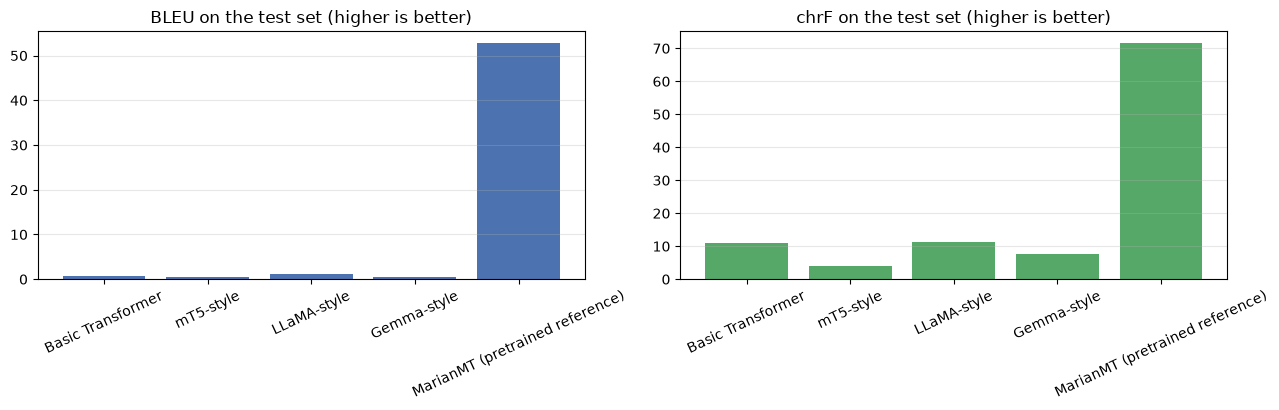

In [13]:
os.makedirs('figures', exist_ok=True)
names = list(results)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(names, [results[n]['bleu'] for n in names], color='#4C72B0')
axes[0].set_title('BLEU on the test set (higher is better)')
axes[1].bar(names, [results[n]['chrf'] for n in names], color='#55A868')
axes[1].set_title('chrF on the test set (higher is better)')
for ax in axes:
    ax.tick_params(axis='x', rotation=25); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('figures/quality.png', dpi=130, bbox_inches='tight'); plt.show()

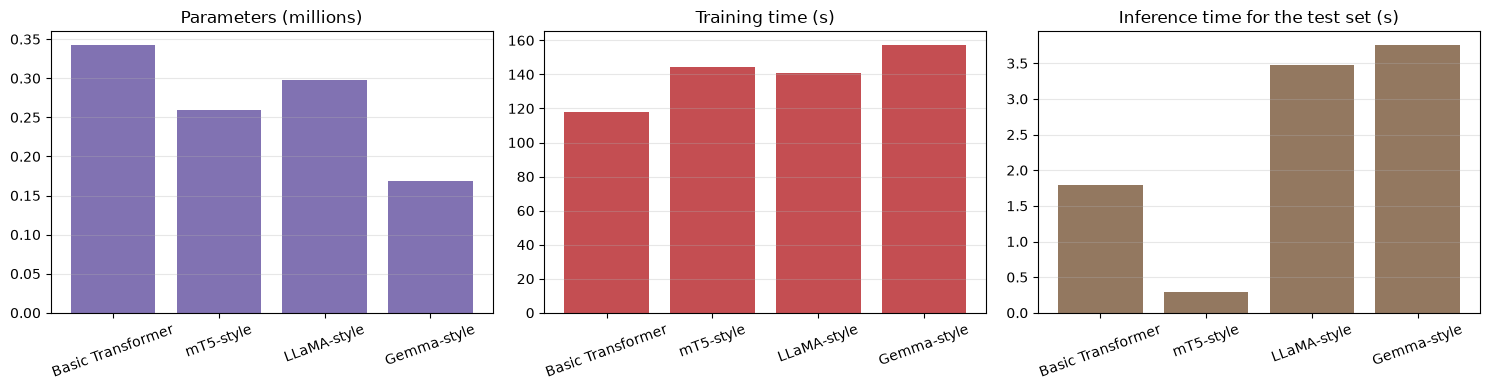

In [14]:
trained = ['Basic Transformer', 'mT5-style', 'LLaMA-style', 'Gemma-style']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
axes[0].bar(trained, [results[n]['params']/1e6 for n in trained], color='#8172B2')
axes[0].set_title('Parameters (millions)')
axes[1].bar(trained, [results[n]['train_s'] for n in trained], color='#C44E52')
axes[1].set_title('Training time (s)')
axes[2].bar(trained, [results[n]['infer_s'] for n in trained], color='#937860')
axes[2].set_title('Inference time for the test set (s)')
for ax in axes:
    ax.grid(alpha=0.3, axis='y'); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('figures/cost.png', dpi=130, bbox_inches='tight'); plt.show()

## 6. Decoding analysis

The README checklist asks for a sampling-temperature analysis. In translation, temperature shapes the
decoding distribution in the same way it does in text generation. Using the Basic Transformer we
compare greedy decoding with temperature sampling at 0.7, 1.0 and 1.3, and with top-k filtering, and
report BLEU together with distinct-2 as a rough measure of output variety.

In [15]:
def translate_sampling(model, sp, srcs, temperature=1.0, top_k=None):
    model.eval()
    S = torch.zeros(len(srcs), MAXLEN, dtype=torch.long)
    for i, s in enumerate(srcs):
        a = sp.encode(s, out_type=int)[:MAXLEN-1]
        S[i, 0] = BOS; S[i, 1:1+len(a)] = torch.tensor(a)
    ys = torch.full((len(srcs), 1), BOS, dtype=torch.long)
    done = torch.zeros(len(srcs), dtype=torch.bool)
    with torch.no_grad():
        for _ in range(MAXLEN):
            logits = model(S, ys)[:, -1] / temperature
            if top_k:
                v, _ = torch.topk(logits, top_k)
                logits = torch.where(logits < v[:, -1:], torch.full_like(logits, float('-inf')), logits)
            nxt = torch.multinomial(torch.softmax(logits, -1), 1).squeeze(1)
            ys = torch.cat([ys, nxt.unsqueeze(1)], 1)
            done |= (nxt == EOS)
            if bool(done.all()):
                break
    out = []
    for row in ys[:, 1:]:
        toks = []
        for t in row.tolist():
            if t == EOS: break
            toks.append(t)
        out.append(sp.decode(toks))
    return out

def distinct2(hyps):
    vals = []
    for h in hyps:
        w = h.split(); g = [tuple(w[i:i+2]) for i in range(len(w)-1)]
        if g: vals.append(len(set(g)) / len(g))
    return float(np.mean(vals)) if vals else 0.0

bt, _ = build_model('Basic Transformer', V)
bt.load_state_dict(torch.load(f'models/{safe("Basic Transformer")}.pt', map_location='cpu'))
bt.eval()
dec_rows = []
for label, kw in [('greedy', {'temperature': 0.0001}), ('T=0.7', {'temperature': 0.7}),
                  ('T=1.0', {'temperature': 1.0}), ('T=1.3', {'temperature': 1.3}),
                  ('T=1.0, top-k=20', {'temperature': 1.0, 'top_k': 20})]:
    hyps = translate_sampling(bt, sp, srcs, **kw)
    dec_rows.append((label, sacrebleu.corpus_bleu(hyps, [refs]).score,
                     sacrebleu.corpus_chrf(hyps, [refs]).score, distinct2(hyps)))
print(f"{'Decoding':18s}{'BLEU':>8}{'chrF':>8}{'distinct-2':>12}")
for a, b, c, d in dec_rows:
    print(f'{a:18s}{b:>8.2f}{c:>8.2f}{d:>12.3f}')

Decoding              BLEU    chrF  distinct-2
greedy                0.71   10.93       0.973
T=0.7                 1.10   12.24       0.998
T=1.0                 0.56   11.48       1.000
T=1.3                 0.23   11.73       1.000
T=1.0, top-k=20       0.94   11.12       1.000


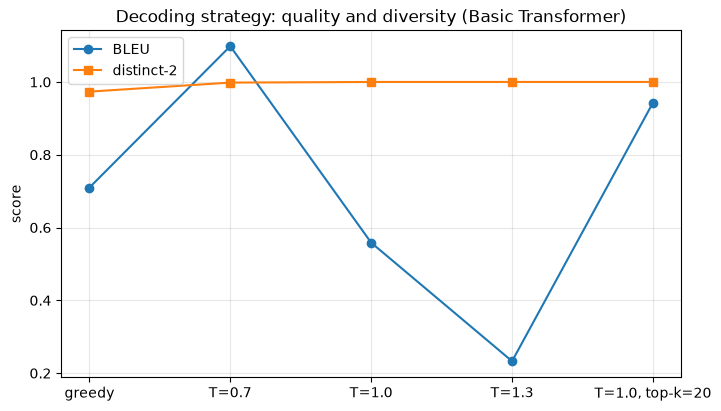

In [16]:
plt.figure(figsize=(8, 4.5))
labels = [r[0] for r in dec_rows]
plt.plot(labels, [r[1] for r in dec_rows], marker='o', label='BLEU')
plt.plot(labels, [r[3] for r in dec_rows], marker='s', label='distinct-2')
plt.title('Decoding strategy: quality and diversity (Basic Transformer)')
plt.ylabel('score'); plt.grid(alpha=0.3); plt.legend()
plt.savefig('figures/decoding.png', dpi=130, bbox_inches='tight'); plt.show()

## 7. Qualitative examples

These are the first test sentences translated by each system, used in the discussion of hallucination,
cultural misrepresentation and inappropriate translation.

In [17]:
for i in range(min(6, len(srcs))):
    print(f'--- sentence {i+1} ---')
    print(' EN  :', srcs[i])
    print(' REF :', refs[i])
    for name in translations:
        print(f' {name[:18]:18s}:', translations[name][i])
    print()

--- sentence 1 ---
 EN  : - Pét'a, hurry up.
 REF : -Peĉjo, rapidu.
 Basic Transformer : - Ĉu mi ne estas, ke mi ne ne estas.
 mT5-style         : - - - - - - - - - - - - -
 LLaMA-style       : - Dankon, ke vi ne estas?
 Gemma-style       : La kondi la kondi la kondondond
 MarianMT (pretrain: - Pacu, rapidu.

--- sentence 2 ---
 EN  : Look. She wants to refiill the tub.
 REF : Aha, ŝi provas replenigi la kuvon
 Basic Transformer : La ku, ke mi fi la fbon
 mT5-style         : Lai la
 LLaMA-style       : Mi ne volas, ke vi ne estas en la konduk
 Gemma-style       : - - - - - - - - - - - -
 MarianMT (pretrain: Ŝi volas refiĉi la kaŭvon.

--- sentence 3 ---
 EN  : We have decided to adopt your idea.
 REF : Ni decidis adopti vian ideon.
 Basic Transformer : Ni estas la kondis la konda.
 mT5-style         : Laii.
 LLaMA-style       : Ni ne scias, ke vi ne estas en la konduk
 Gemma-style       : Mi ne povas povas povas povas povas povas povas povas povas povas povas povas
 MarianMT (pretrain:

## 8. Saving results

In [18]:
out = {'config': {'vocab': V, 'maxlen': MAXLEN, 'batch': BATCH, 'lr': LR, 'epochs': EPOCHS,
                  'train_n': len(train), 'test_n': len(srcs), 'd_model': D_MODEL,
                  'max_words': MAX_WORDS},
       'results': results,
       'decoding': [{'setting': a, 'bleu': b, 'chrf': c, 'distinct2': d} for a, b, c, d in dec_rows],
       'examples': [{'en': srcs[i], 'ref': refs[i], **{k: translations[k][i] for k in translations}}
                    for i in range(min(20, len(srcs)))]}
json.dump(out, open('results.json', 'w'), indent=2, ensure_ascii=False)
print('saved results.json')
print('corpus: %d training pairs, %d validation, %d test sentences' % (len(train), len(val), len(srcs)))

saved results.json
corpus: 6496 training pairs, 403 validation, 82 test sentences


## 9. Summary

The four architectures are compared on BLEU, chrF, parameter count, training time and inference time,
with a pretrained MarianMT model as a reference. The accompanying report and `README.md` discuss how the
encoder-decoder and decoder-only families differ, and the ethical risks visible in the translations.